In [36]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [37]:
df=pd.read_csv("spam.csv",encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [38]:
df.shape

(5572, 5)

In [39]:

df = df.rename(columns={'v1': 'label', 'v2': 'message'})
df_clean = df[['label', 'message']].copy()
df_clean.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [40]:
df_clean.shape

(5572, 2)

In [41]:
df_clean.isnull().sum()

label      0
message    0
dtype: int64

In [42]:
df_clean.isna().sum()

label      0
message    0
dtype: int64

In [43]:
doublons_av = df_clean.duplicated().sum()
print(f"doublons avant suppression {doublons_av}")

doublons avant suppression 403


In [44]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
doublons_sup = df_clean.duplicated().sum()
print(f"doublons apres suppression {doublons_sup}")
print(df_clean.shape)

doublons apres suppression 0
(5169, 2)


In [45]:
print(df_clean['label'].value_counts())
print(df_clean['label'].value_counts(normalize=True).round(3))

label
ham     4516
spam     653
Name: count, dtype: int64
label
ham     0.874
spam    0.126
Name: proportion, dtype: float64


## Exploration et nettoyage des données

- **Données** : 5 572 messages SMS en anglais, étiquetés ham (légitime) ou spam. Fichier lu avec l'encodage `latin-1`.
- **Colonnes** : seules `v1` (étiquette) et `v2` (texte) sont conservées, renommées `label` et `message`. Les trois autres sont vides.
- **Valeurs manquantes** : aucune.
- **Doublons** : 403 supprimés avant le découpage, pour éviter qu'un même message se retrouve dans le train et le test. Il reste 5 169 messages.
- **Classes** : 4 516 ham (87,4 %) et 653 spam (12,6 %). Elles sont déséquilibrées.
- **Conséquence** : un modèle qui répondrait toujours « ham » aurait 87,4 % d'accuracy sans détecter aucun spam. J'évalue donc avec la precision, le recall et le F1-score, et j'utilise `stratify` au découpage.

## le prétraitement du texte

In [46]:
print(df_clean.columns)

Index(['label', 'message'], dtype='str')


In [47]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def nettoyer_texte(texte):
    texte = texte.lower()
    texte = re.sub(r'[^a-z\s]', ' ', texte)
    mots = texte.split()
    mots = [m for m in mots if m not in stop_words]
    mots = [stemmer.stem(m) for m in mots]
    return ' '.join(mots)

df_clean['message_clean'] = df_clean['message'].apply(nettoyer_texte)
print(df_clean[['message', 'message_clean']].head())

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\balbi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                       message_clean  
0  go jurong point crazi avail bugi n great world...  
1                              ok lar joke wif u oni  
2  free entri wkli comp win fa cup final tkt st m...  
3                u dun say earli hor u c alreadi say  
4               nah think goe usf live around though  


In [48]:
print(df_clean['message_clean'].isna().sum())
print((df_clean['message_clean'].str.strip() == '').sum())

0
7


## Prétraitement du texte

Chaque message est transformé en 5 étapes :
- **Minuscules** : « Free » et « free » deviennent le même mot.
- **Retrait de la ponctuation et des chiffres** : seules les lettres sont gardées.
- **Stopwords anglais** : suppression des mots très courants (the, is, to...) peu informatifs.
- **Stemming (Porter)** : chaque mot est ramené à sa racine (`winning` - `win`).
- **Recollage** en une chaîne `message_clean`.

**Exemple** : « Ok lar... Joking wif u oni... » - « ok lar joke wif u oni ».

**Ce que le nettoyage fait perdre** : les chiffres et symboles (`£1000`, `150p`, `2`), qui sont souvent des indices de spam. Le stemming produit aussi des racines étranges (`entri`).

**Messages vides** : 7 messages ne contiennent plus aucun mot après nettoyage 

## suppression des messages vides

In [49]:
df_clean = df_clean[df_clean['message_clean'].str.strip() != ''].reset_index(drop=True)
print(df_clean.shape)
print((df_clean['message_clean'].str.strip() == '').sum())

(5162, 3)
0


In [50]:
## verification 
print(df_clean['label'].value_counts())
print(df_clean['label'].value_counts(normalize=True).round(3))

label
ham     4509
spam     653
Name: count, dtype: int64
label
ham     0.873
spam    0.127
Name: proportion, dtype: float64


- **Messages vides** : 7 messages (tous ham) ne contenaient plus aucun mot après nettoyage ; je les ai supprimés. Il reste 5 162 messages : 4 509 ham (87,3 %) et 653 spam (12,7 %).

## visualisation

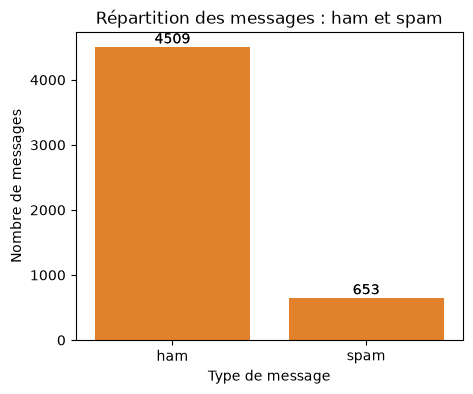

In [51]:
import os

os.makedirs("images", exist_ok=True)

plt.figure(figsize=(5, 4))
sns.countplot(data=df_clean, x="label", order=["ham", "spam"])
plt.title("Répartition des messages : ham et spam")
plt.xlabel("Type de message")
plt.ylabel("Nombre de messages")

ax = sns.countplot(data=df_clean, x="label", order=["ham", "spam"])
for barre in ax.patches:
    ax.annotate(int(barre.get_height()),
                (barre.get_x() + barre.get_width() / 2, barre.get_height()),
                ha="center", va="bottom")
plt.savefig("images/repartition_classes.png", dpi=150, bbox_inches="tight")
plt.show()

### Répartition des classes
Après nettoyage, le jeu de données contient 5 162 messages : 4 509 ham (87,3 %) et 653 spam (12,7 %). La barre ham est environ sept fois plus haute que la barre spam : les classes sont déséquilibrées. L'accuracy seule serait donc trompeuse, d'où l'usage de la precision, du recall et du F1-score.

## entrainement

In [59]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X = df_clean['message_clean']
y = df_clean['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

(4129,) (1033,)
label
ham     0.874
spam    0.126
Name: proportion, dtype: float64
label
ham     0.873
spam    0.127
Name: proportion, dtype: float64


## Découpage train/test

Les données sont séparées en 80 % pour l'entraînement (4 129 messages) et 20 % pour le test (1 033 messages), avec `random_state=42` pour que le résultat soit reproductible.

Le paramètre `stratify` conserve la proportion de spam dans les deux ensembles (12,6 % en train, 12,7 % en test). C'est indispensable ici, car les spams sont peu nombreux.

Le découpage est fait **avant** le TF-IDF : le vocabulaire et les poids sont calculés sur le train seulement, pour ne pas utiliser d'informations du test (fuite de données).

# TF-IDF

In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [54]:
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Train :", X_train_tfidf.shape)
print("Test  :", X_test_tfidf.shape)
print("Taille du vocabulaire :", len(tfidf.get_feature_names_out()))

Train : (4129, 5527)
Test  : (1033, 5527)
Taille du vocabulaire : 5527


## Extraction de caractéristiques : TF-IDF

Un modèle ne lit pas du texte, il lit des nombres. TF-IDF transforme chaque message en un vecteur de poids, un par mot du vocabulaire.

- **TF** (Term Frequency) : combien de fois un mot apparaît dans un message.
- **IDF** (Inverse Document Frequency) : à quel point le mot est rare dans l'ensemble des messages. Un mot présent partout (« get ») a un IDF faible ; un mot rare (« prize ») a un IDF élevé.
- **TF-IDF = TF × IDF** : un mot pèse lourd s'il est fréquent dans ce message mais rare dans les autres. C'est ce qui permet de repérer les mots caractéristiques d'un spam.

Le vocabulaire et les poids sont calculés sur le train uniquement, puis appliqués au test, pour éviter toute fuite de données.
Après TF-IDF, chaque message est représenté par un vecteur de 5 527 valeurs (une par mot du vocabulaire appris sur le train). La matrice d'entraînement a pour forme (4 129, 5 527) et celle de test (1 033, 5 527).

### les mots les plus loourd 

In [55]:

mots = tfidf.get_feature_names_out()
ligne = X_train_tfidf[0].toarray().ravel()
top = np.argsort(ligne)[::-1][:5]
print([(mots[i], round(ligne[i], 3)) for i in top])

[('aftr', np.float64(0.5)), ('clean', np.float64(0.449)), ('decim', np.float64(0.429)), ('hous', np.float64(0.391)), ('lt', np.float64(0.271))]


## predition

Multinomial Naive Bayes

In [56]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Entrainement et prédiction

In [57]:
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
y_pred_nb = nb.predict(X_test_tfidf)

evaluation

In [58]:
acc_nb = accuracy_score(y_test, y_pred_nb)
print(f"Accuracy : {acc_nb:.3f}")
print("\nClassification Report :")
print(classification_report(y_test, y_pred_nb))

Accuracy : 0.972

Classification Report :
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       902
        spam       1.00      0.78      0.88       131

    accuracy                           0.97      1033
   macro avg       0.98      0.89      0.93      1033
weighted avg       0.97      0.97      0.97      1033



### Résultats : Multinomial Naive Bayes
- **Accuracy** : 0,972, contre 0,873 pour un modèle qui répondrait toujours « ham ».
- **Precision (spam)** : 1,00. Aucun message légitime n'est classé spam.
- **Recall (spam)** : 0,78. Environ 22 % des spams (environ 29 sur 131) ne sont pas détectés.
- **F1 (spam)** : 0,88.
- **Interprétation** : le modèle est très prudent : il ne classe en spam que les cas certains, mais laisse passer une partie des spams. 


Logistic Regression

Entrainement et prediction 

In [63]:
lr = LogisticRegression(max_iter=1000, random_state=42,class_weight="balanced")
lr.fit(X_train_tfidf, y_train)
y_pred_lr = lr.predict(X_test_tfidf)

Evaluation

In [64]:
acc_lr = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy : {acc_lr:.3f}")
print("\nClassification Report :")
print(classification_report(y_test, y_pred_lr))

Accuracy : 0.980

Classification Report :
              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       902
        spam       0.89      0.95      0.92       131

    accuracy                           0.98      1033
   macro avg       0.94      0.97      0.96      1033
weighted avg       0.98      0.98      0.98      1033



matrice de confusion 

[[887  15]
 [  6 125]]


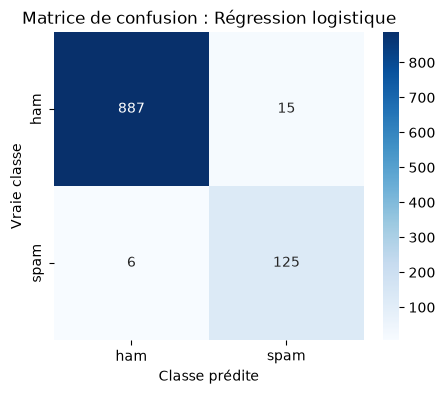

In [65]:
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=["ham", "spam"])
print(cm_lr)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.title("Matrice de confusion : Régression logistique")
plt.xlabel("Classe prédite")
plt.ylabel("Vraie classe")
plt.savefig("images/confusion_lr.png", dpi=150, bbox_inches="tight")
plt.show()

### Comparaison des modèles

Trois modèles sont comparés sur le même jeu de test (1 033 messages, dont 131 spams).

- **Naive Bayes** : accuracy 0,972, precision 1,00, recall 0,78, F1 0,88. Aucun message légitime n'est bloqué, mais environ 29 spams ne sont pas détectés.
- **Régression logistique** : accuracy 0,965, precision 0,98, recall 0,74, F1 0,84. 2 messages légitimes bloqués, 34 spams non détectés.
- **Régression logistique `balanced`** : accuracy 0,980, precision 0,89, recall 0,95, F1 0,92. 15 messages légitimes bloqués, 6 spams non détectés.

Les deux premiers modèles sont très prudents : precision élevée, mais recall limité. Donner plus de poids à la classe spam (`class_weight="balanced"`) fait passer les spams non détectés de 34 à 6, au prix de 13 messages légitimes bloqués en plus.

**Modèle retenu** : la régression logistique équilibrée, qui a la meilleure accuracy, le meilleur recall et le meilleur F1. Pour un filtre anti-spam, laisser passer des messages frauduleux est le risque principal. Naive Bayes reste préférable si l'on veut éviter à tout prix de bloquer un message légitime.

**Limites** : un seul découpage, 131 spams en test, et les trois modèles sont comparés sur le même jeu de test.

#### Pourquoi le recall est important pour détecter le spam
Le recall mesure la part des vrais spams que le modèle détecte. Un recall faible laisse passer des messages frauduleux (arnaques, liens malveillants) jusqu'à l'utilisateur.
L'accuracy ne suffit pas : avec 87,3 % de ham, un modèle qui répondrait toujours « ham » aurait 87,3 % d'accuracy et un recall de 0.
Il faut cependant équilibrer avec la precision : bloquer un message légitime (faux positif) peut aussi coûter cher. Le F1-score résume ce compromis. Ici, Naive Bayes a une precision de 1,00 mais un recall de 0,78 : il est très prudent. Selon le contexte, on peut accepter plus de faux positifs pour détecter davantage de spams.